# Лабораторная работа №7
## Введение
**Название:** деревья решений и ансамбли на их основе

**Цели:** 
1. освоить принципы построения и настройки дерева решений с помощью sklearn.tree.DecisionTreeClassifie;
2. познакомиться с базовыми ансамблевыми методами: бэггинг (Bagging) и
бустинг (Boosting);
3. сравнить эффективность одиночного дерева и ансамблей на практическом примере.

**Описание показателей (вариант 15):**
- age – возраст
- workclass – класс работы
- fnlwgt – показывает сколько людей с такими же характеристиками существует
- education – образование
- education-num – число образований
- marital-status – семейное положение
- occupation – вид деятельности
- relationship – степень родства
- race – раса
- sex – пол
- capital-gain – прирост капитала
- capital-loss – убыток капитала
- hours-per-week – часов в неделю
- native-country – страна происхождения
- salary – зарплата ((<=50K, >50K) – целевая переменная)

## 1. Импорт библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 2. Загрузка и первичный анализ

In [3]:
df = pd.read_csv('salary.csv', skipinitialspace=True)
# разделение данных на признаки и целевую переменную
y = df['salary']
X = df.drop('salary', axis=1)

print("Размерность признаков:", X.shape)
print("Названия признаков:", X.columns.tolist())
print("Размерность целевой переменной:", y.shape)
print("Уникальные значения целевой переменной:", y.unique())
print("Первые 5 строк признаков:")
print(X.head())

Размерность признаков: (32561, 14)
Названия признаков: ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']
Размерность целевой переменной: (32561,)
Уникальные значения целевой переменной: <StringArray>
['<=50K', '>50K']
Length: 2, dtype: str
Первые 5 строк признаков:
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male 

## 3. Разделение данных на обучающую и тестовую выборки

In [4]:
# Кодируем категориальные признаки
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)
print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (26048, 100)
Размер тестовой выборки: (6513, 100)


## 4. Построение и оценка базового дерева решений

In [5]:
base_dt = DecisionTreeClassifier(random_state=42)
base_dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Делаем прогнозы и оцениваем точность

In [6]:
y_pred_base = base_dt.predict(X_test)
accuracy_base = accuracy_score(y_test, y_pred_base)
print(f"Точность базового дерева: {100*accuracy_base:.4f}%")

Точность базового дерева: 81.3604%


Визуализируем дерево, не ограниченное

Используем max_depth для читаемости

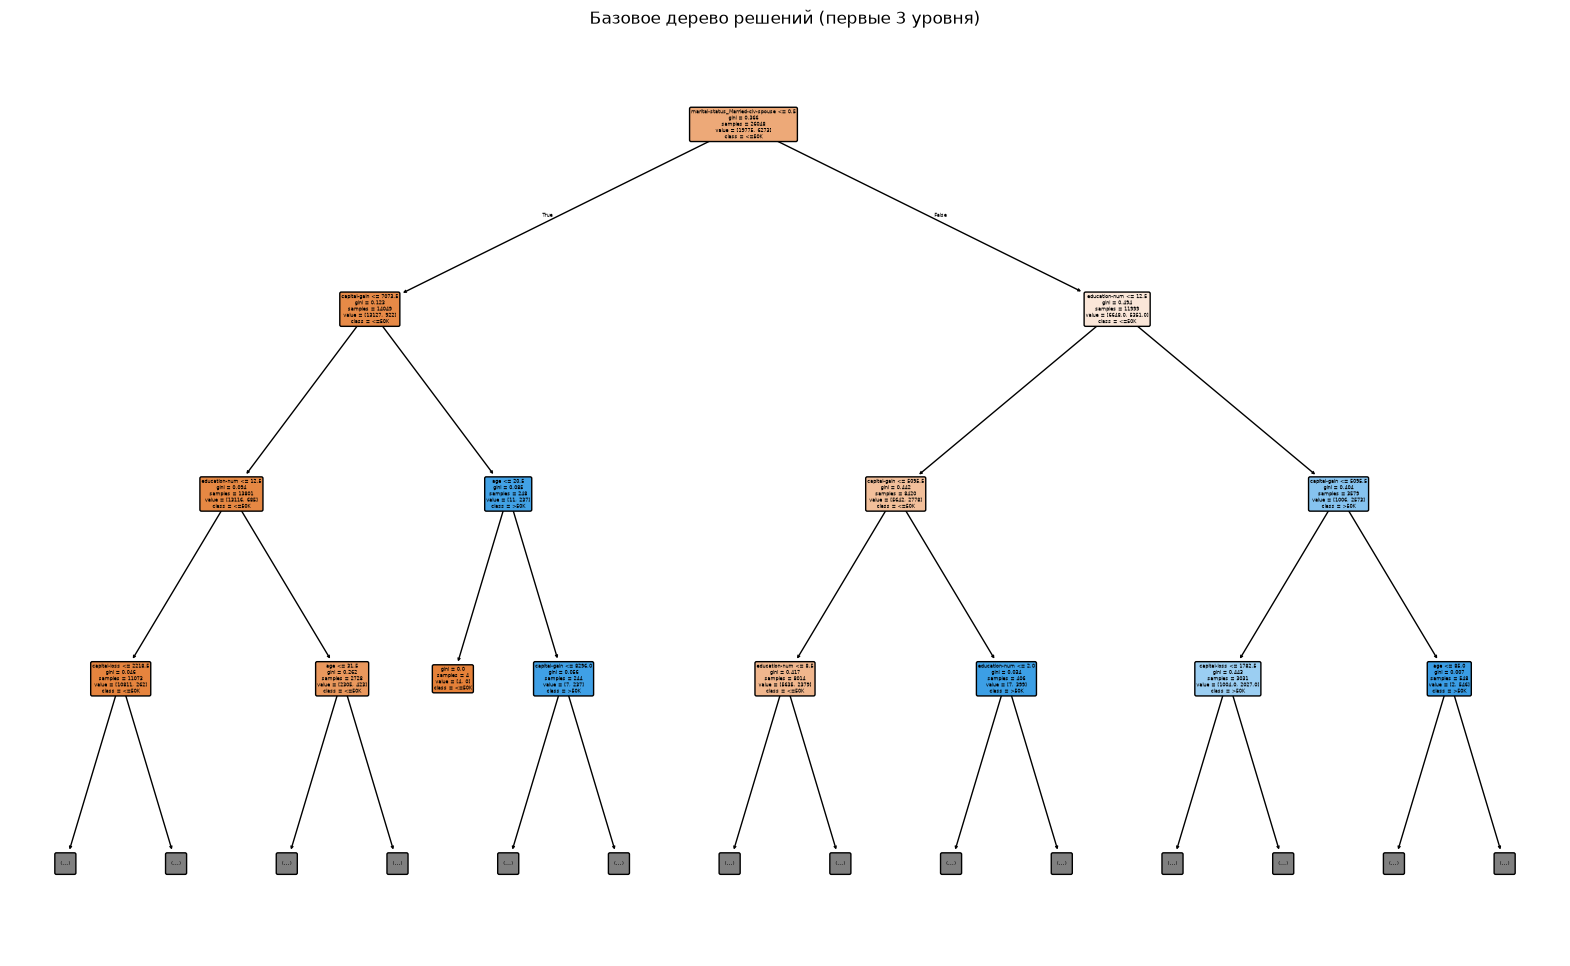

In [7]:
plt.figure(figsize=(20, 12))
plot_tree(base_dt, filled=True, feature_names=X.columns,
           class_names=sorted(y.unique()), rounded=True, max_depth=3)
plt.title("Базовое дерево решений (первые 3 уровня)")
plt.show()

## 5. Настройка гиперпараметров

In [8]:
tuned_dt = DecisionTreeClassifier(max_depth=3, random_state=42)
tuned_dt.fit(X_train, y_train)
y_pred_tuned = tuned_dt.predict(X_test)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"Точность настроенного дерева (max_depth=3) на тесте: {100*accuracy_tuned:.4f}%")

Точность настроенного дерева (max_depth=3) на тесте: 84.6614%


Кросс-валидация для более высокой оценки

In [12]:
cv_scores_base = cross_val_score(base_dt, X, y, cv=5)
cv_scores_tuned = cross_val_score(tuned_dt, X, y, cv=5)
print(f"Кросс-валидация, базовое дерево: {np.mean(cv_scores_base) * 100:.4f}% (+/- {np.std(cv_scores_base) * 200:.4f}%)")
print(f"Кросс-валидация, настроенное дерево: {np.mean(cv_scores_tuned) * 100:.4f}% (+/- {np.std(cv_scores_tuned) * 200:.4f}%)")

Кросс-валидация, базовое дерево: 81.1462% (+/- 0.9653%)
Кросс-валидация, настроенное дерево: 84.3801% (+/- 0.8251%)


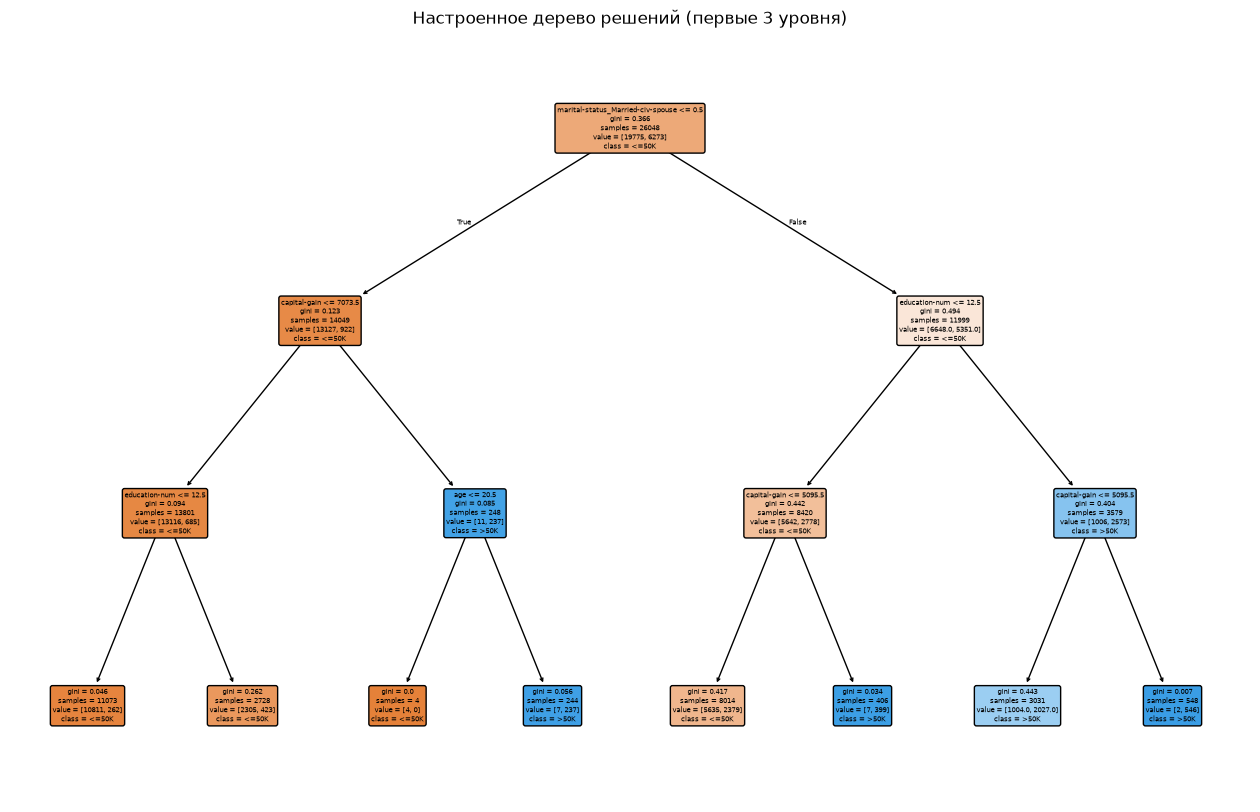

In [13]:
plt.figure(figsize=(16,10))
plot_tree(tuned_dt, filled=True, feature_names=X.columns,
           class_names=sorted(y.unique()), rounded=True)
plt.title("Настроенное дерево решений (первые 3 уровня)")
plt.show()

Важность признаков (топ 10)

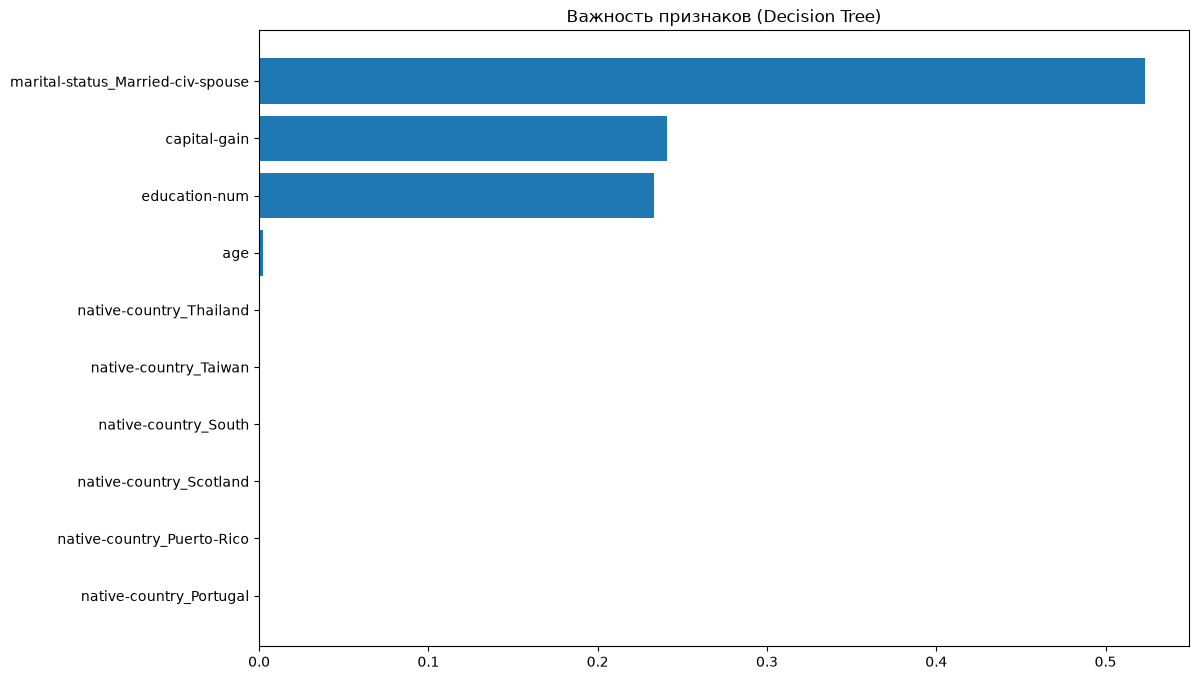

In [16]:
importances = tuned_dt.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(12, 8))
plt.title("Важность признаков (Decision Tree)")
plt.barh(range(10), importances[indices][:10])
plt.yticks(range(10), [X.columns[i] for i in indices[:10]])
plt.gca().invert_yaxis()
plt.show()

## 6. Ансамбли: случайный лес (бэггинг)

Создаём и обучаем случайный лес

In [19]:
rf = RandomForestClassifier(n_estimators=100, random_state=42) #100 деревьев
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Прогноз и оценка

In [32]:
y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Точность случайного леса: {accuracy_rf*100:.4f}%")

Точность случайного леса: 86.0740%


Важность признаков с одиночным деревом

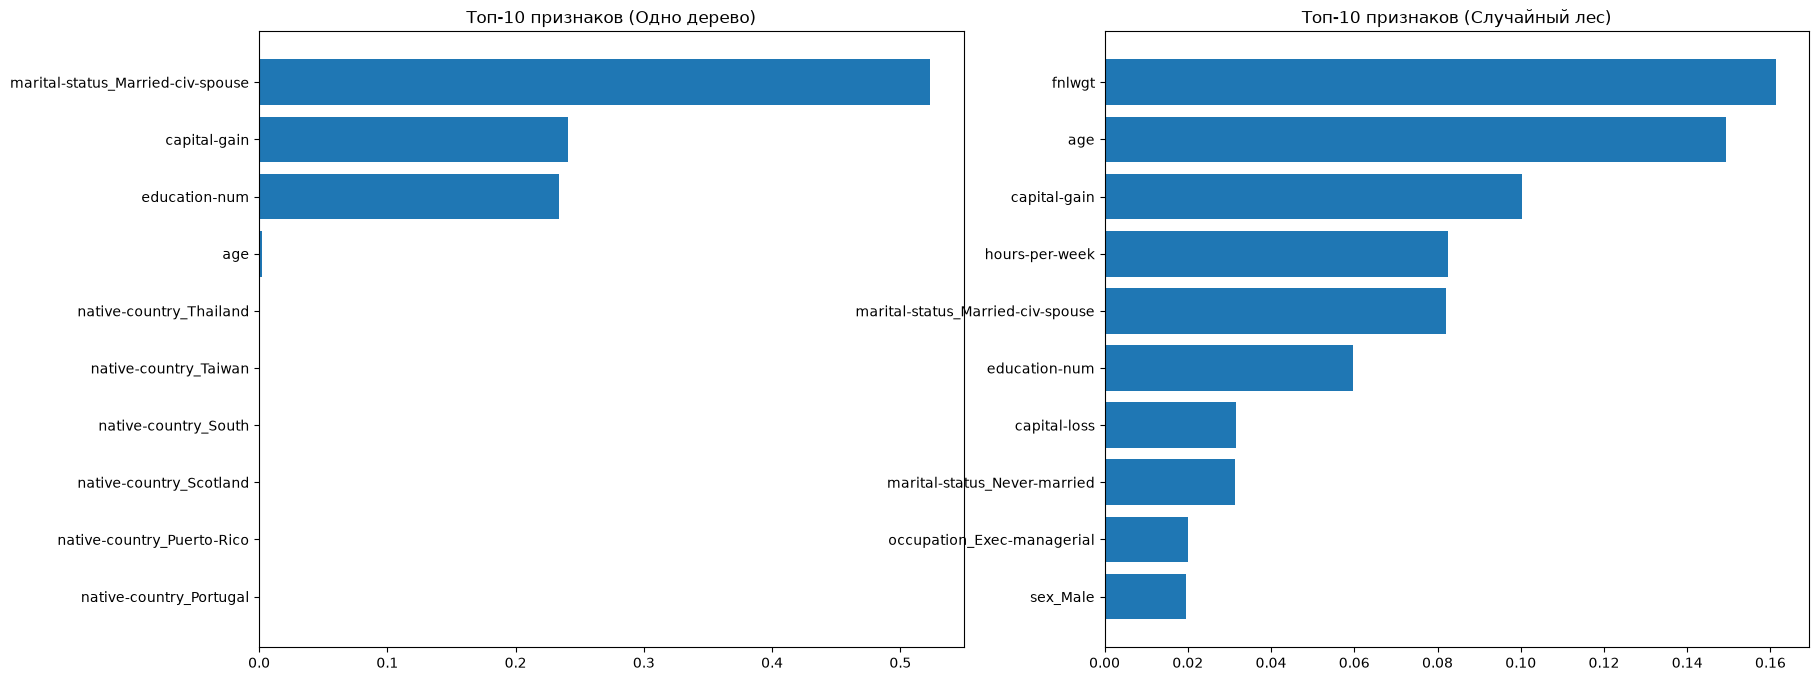

In [24]:

rf_importances = rf.feature_importances_
indices_rf = np.argsort(rf_importances)[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
ax1.barh(range(10), importances[indices][:10])
ax1.set_title("Топ-10 признаков (Одно дерево)")
ax1.set_yticks(range(10))
ax1.set_yticklabels([X.columns[i] for i in indices[:10]])
ax1.invert_yaxis()

ax2.barh(range(10), rf_importances[indices_rf][:10])
ax2.set_title("Топ-10 признаков (Случайный лес)")
ax2.set_yticks(range(10))
ax2.set_yticklabels([X.columns[i] for i in indices_rf[:10]])
ax2.invert_yaxis()
plt.show()

## 7. Ансамбли: грандиентный бустинг (Boosting)

Создадим и обучим, создадим прогноз и оценим его точность

In [26]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Точность бустинга на тесте: {accuracy_gb*100:.4f}%")

Точность бустинга на тесте: 86.9338%


## 8. Сравнение всех моделей в сводной таблице

In [30]:
models = {
    'Base Decision Tree': base_dt,
    'Tuned Decision Tree': tuned_dt,
    'Random Forest': rf,
    'Gradient Boosting': gb
}

results = {}
for name, model in models.items():
    # Обучаем на полном тренировочном наборе
    if name not in ['Base Decision Tree', 'Tuned Decision Tree']:
        model.fit(X_train, y_train)
    # Считаем accuracy
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    results[name] = {'Train Accuracy': train_acc, 'Test Accuracy': test_acc}

Вывод результатов в виде df и bar-plot

                     Train Accuracy  Test Accuracy
Base Decision Tree         0.999962       0.813604
Tuned Decision Tree        0.843213       0.846614
Random Forest              0.999962       0.860740
Gradient Boosting          0.869472       0.869338


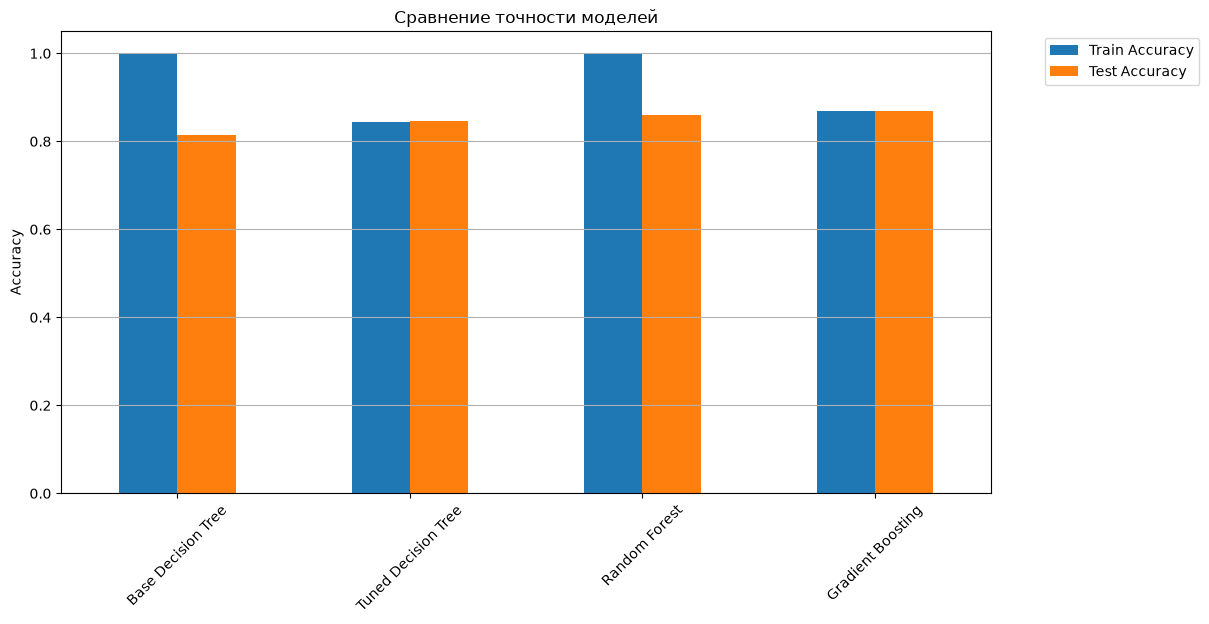

In [31]:
results_df = pd.DataFrame(results).T
print(results_df)

results_df[['Train Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(12, 6))
plt.title('Сравнение точности моделей')
plt.ylabel ('Accuracy')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis="y")
plt.show()

По тестовой выборке хуже всего показало себя ненастроенное дерево — 81.4% при почти 100% на train - выраженное переобучение. Настройка дерева подняла тестовую выборку до 84.7% и убрала разрыв с train. Random Forest дал 86.1% на тесте, но при 99.996% на тренировочной выборке - сильно переобучен. Лучший результат у Gradient Boosting: 86.9% на тестовой и столько же на тренировочной выборке, без разрыва. Поэтому, несмотря на высокий показатель леса, предпочтительнее бустинг: он точнее на новых данных и не переобучается.